# Notebook 5 – Bivariate Analysis

Study the relationship between **two variables**.

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet).
# This loader checks common local locations first, then tries the public source.
from pathlib import Path

TELCO_URLS = [
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/main/data/Telco-Customer-Churn.csv",
]

candidate_names = [
    "telco.csv",
    "Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]

search_roots = [Path.cwd(), *list(Path.cwd().parents)[:4]]
local_candidates = []
for root in search_roots:
    for name in candidate_names:
        local_candidates.extend([
            root / name,
            root / "data" / name,
            root / "Datasets" / name,
            root / "dataset" / name,
        ])

local_path = next((p.resolve() for p in local_candidates if p.is_file()), None)

if local_path is not None:
    df_raw = pd.read_csv(local_path)
    print("Loaded local dataset:", local_path)
else:
    load_errors = []
    df_raw = None
    for url in TELCO_URLS:
        try:
            df_raw = pd.read_csv(url)
            print("Loaded dataset from public source.")
            break
        except Exception as exc:
            load_errors.append(f"{url} -> {type(exc).__name__}: {exc}")
    if df_raw is None:
        raise FileNotFoundError(
            "Could not find the Telco dataset locally, and downloading it failed. "
            "Place the original Telco Customer Churn CSV in a 'data' folder next to "
            "your notebooks (or in the parent folder's 'data' folder), name it "
            "'telco.csv' or 'Telco-Customer-Churn.csv', and rerun this cell. "
            "If using a URL, check your internet connection.\n\nDetails:\n"
            + "\n".join(load_errors)
        )

df = df_raw.copy()
print("Loaded:", df.shape)


# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


### Topic Explanation

This topic focuses on numerical vs numerical. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 1. Numerical vs Numerical

### 1. Concept
Examine how two numeric variables move together using a **scatter plot** and a **correlation coefficient**. Pearson measures *linear* association; Spearman measures *monotonic* (rank) association. Range –1 to +1.

### 2. Example
*Simple:* Age vs salary, Income vs spending.  
*Business:* do customers who stay longer pay more per month?  
*AI/ML use:* strongly related features are redundant; strong relation with a target is predictive.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [2]:
pairs = [("tenure", "MonthlyCharges"), ("tenure", "TotalCharges"), ("MonthlyCharges", "TotalCharges")]
rows = []
for a, b in pairs:
    d = df[[a, b]].dropna()
    rows.append((a, b, d[a].corr(d[b]), d[a].corr(d[b], method="spearman")))
display(pd.DataFrame(rows, columns=["x", "y", "pearson", "spearman"]).round(3))

,x,y,pearson,spearman
0,tenure,MonthlyCharges,0.248,0.276
1,tenure,TotalCharges,0.826,0.889
2,MonthlyCharges,TotalCharges,0.651,0.638


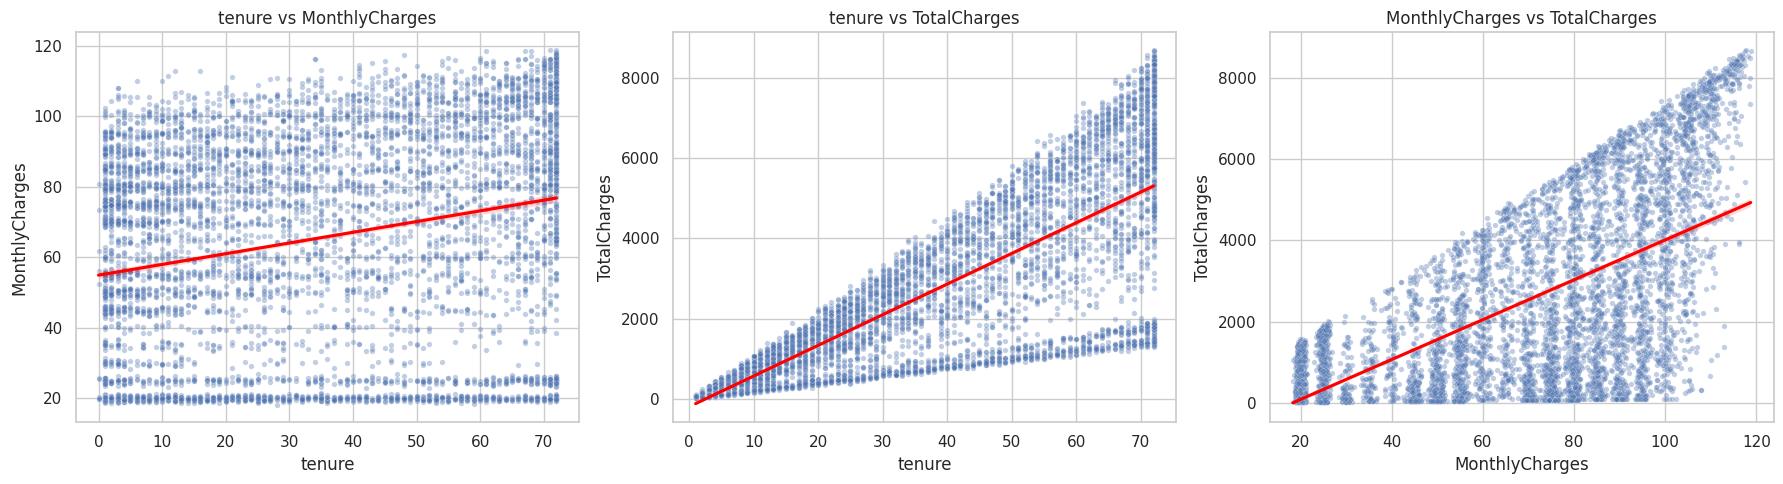

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (a, b) in zip(axes, pairs):
    sns.scatterplot(data=df, x=a, y=b, alpha=0.35, s=15, ax=ax)
    sns.regplot(data=df.dropna(subset=[a, b]), x=a, y=b, scatter=False, color="red", ax=ax)
    ax.set_title(f"{a} vs {b}")
plt.tight_layout(); plt.show()

### 5. Interpretation
- `tenure` vs `TotalCharges`: strong positive (≈ 0.83) – longer stay accumulates a bigger total, as expected.  
- `MonthlyCharges` vs `TotalCharges`: moderately strong (≈ 0.65).  
- `tenure` vs `MonthlyCharges`: weak positive (≈ 0.25); the scatter is a wide band with two visible clusters (low-price and high-price plans).

### 6. Insight
`TotalCharges` is essentially `tenure × MonthlyCharges`, a derived quantity. Customer lifetime and price level are only loosely related, so loyalty is not simply about plan price.

### 7. AI/ML Relevance
`TotalCharges` is largely redundant with its two parents – a multicollinearity risk for linear models (explored in Notebook 6).

### Topic Explanation

This topic separates numeric measurements or counts from labels and groups, helping choose suitable summaries and charts.

## 2. Numerical vs Categorical

### 1. Concept
Compare the distribution of a numeric variable across categories with **box plots**, **violin plots** or group statistics (mean/median by group).

### 2. Example
*Simple:* Department vs Salary.  
*Business:* do customers on different contracts pay differently? Do churners have shorter tenure?  
*AI/ML use:* a numeric feature that separates the target classes is predictive.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [4]:
display(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(1))
display(df.groupby("Contract")[["tenure", "MonthlyCharges"]].agg(["mean", "median"]).round(1))
display(df.groupby("InternetService")["MonthlyCharges"].agg(["mean", "median", "std"]).round(1))

tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
Churn                                                         
No      37.6   38.0           61.3   64.4       2555.3  1683.6
Yes     18.0   10.0           74.4   79.6       1531.8   703.6

tenure        MonthlyCharges       
                 mean median           mean median
Contract                                          
Month-to-month   18.0   12.0           66.4   73.2
One year         42.0   44.0           65.0   68.8
Two year         56.7   64.0           60.8   64.4

,mean,median,std
InternetService,,,
DSL,58.1,56.2,16.3
Fiber optic,91.5,91.7,12.7
No,21.1,20.2,2.2


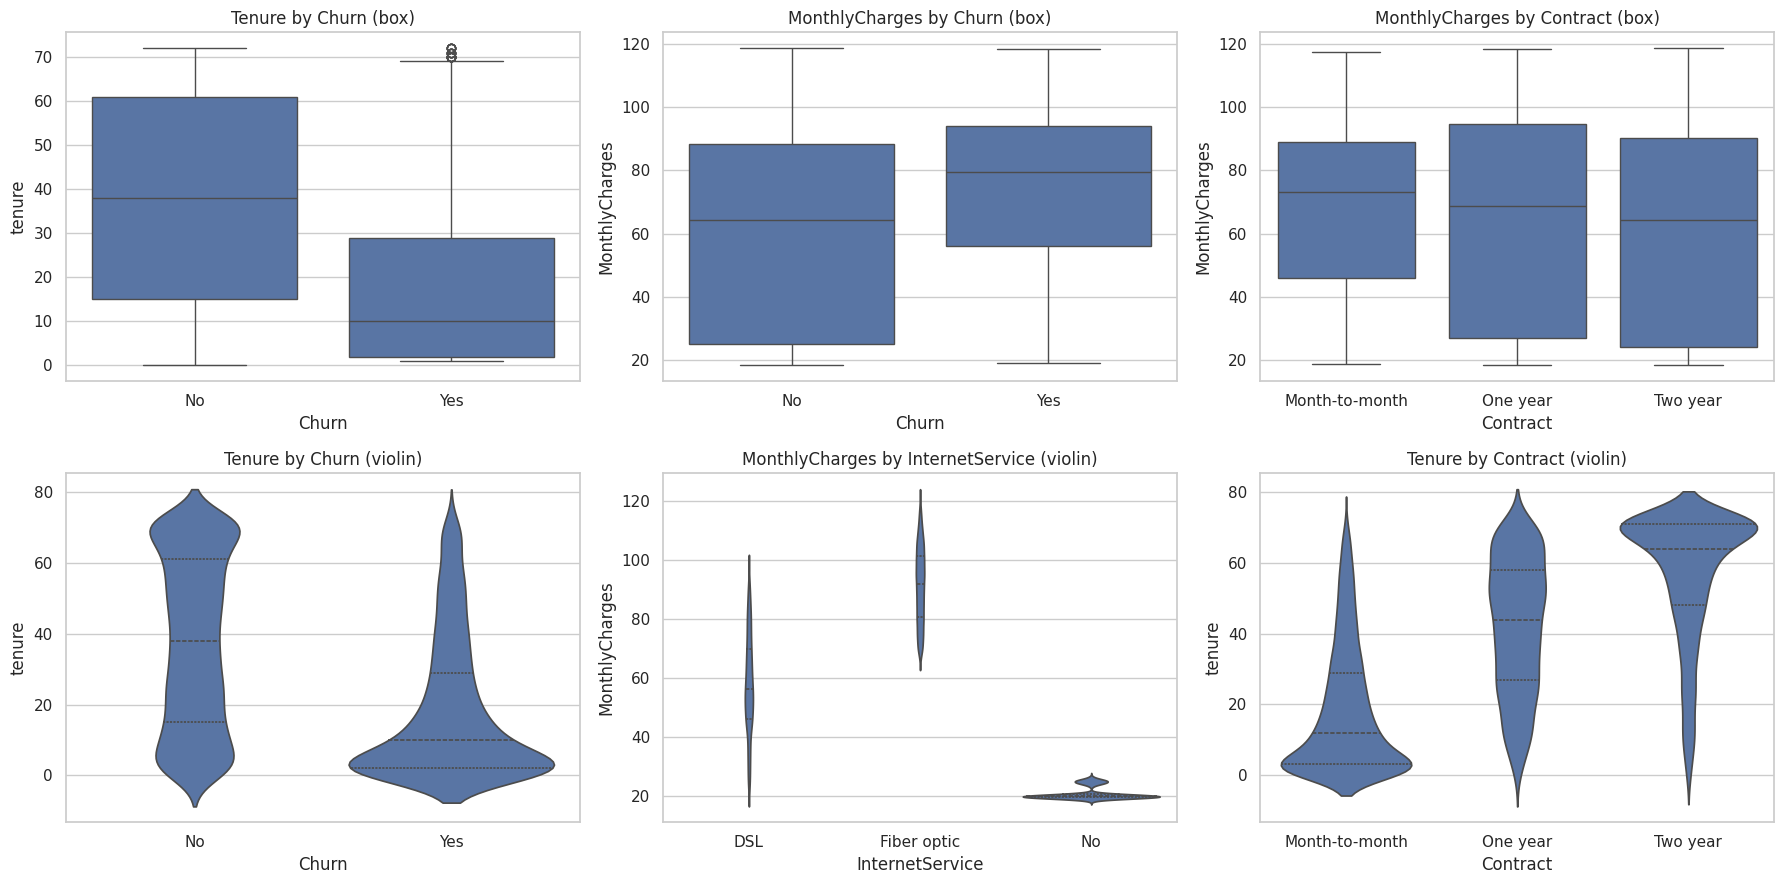

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0, 0]);               axes[0, 0].set_title("Tenure by Churn (box)")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[0, 1]);       axes[0, 1].set_title("MonthlyCharges by Churn (box)")
sns.boxplot(data=df, x="Contract", y="MonthlyCharges", ax=axes[0, 2]);    axes[0, 2].set_title("MonthlyCharges by Contract (box)")
sns.violinplot(data=df, x="Churn", y="tenure", ax=axes[1, 0], inner="quartile");               axes[1, 0].set_title("Tenure by Churn (violin)")
sns.violinplot(data=df, x="InternetService", y="MonthlyCharges", ax=axes[1, 1], inner="quartile"); axes[1, 1].set_title("MonthlyCharges by InternetService (violin)")
sns.violinplot(data=df, x="Contract", y="tenure", ax=axes[1, 2], inner="quartile");            axes[1, 2].set_title("Tenure by Contract (violin)")
plt.tight_layout(); plt.show()

### 5. Interpretation
- **Churn vs tenure:** churners have a median tenure of 10 months vs 38 for non-churners – a very clear separation.  
- **Churn vs MonthlyCharges:** churners pay more (median ≈ \$80 vs ≈ \$64).  
- **InternetService vs MonthlyCharges:** Fiber optic customers pay about \$91 on average vs \$58 for DSL, and ≈ \$21 for no internet.  
- **Contract vs tenure:** two-year contracts concentrate at long tenures; month-to-month at short tenures.

### 6. Insight
Churners are *newer* and *pay more*. The combination of a high bill and a short relationship looks like the high-risk profile. Fibre customers pay a premium and (as seen in Notebook 5-3) churn at higher rates.

### 7. AI/ML Relevance
`tenure` and `MonthlyCharges` are likely strong predictors; violin plots reveal the bimodality that a mean comparison hides.

### Topic Explanation

This topic analyses category counts, proportions, rare levels, cardinality, imbalance, and relationships with the target.

## 3. Categorical vs Categorical

### 1. Concept
Use **cross-tabulation** (counts or row percentages) and **grouped/stacked bar charts**. A **chi-square test** checks whether two categoricals are statistically associated; **Cramér's V** measures strength (0–1).

### 2. Example
*Simple:* Product category vs region.  
*Business:* is churn rate different across contract types?  
*AI/ML use:* identifies categorical features related to the target.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [6]:
for c in ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]:
    ct = pd.crosstab(df[c], df["Churn"])
    pct = pd.crosstab(df[c], df["Churn"], normalize="index").mul(100).round(1)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"\n▶ {c} vs Churn   chi2={chi2:.1f}, p={p:.2e}, Cramér's V={v:.3f}")
    display(pd.concat([ct, pct.add_suffix(' %')], axis=1))


▶ Contract vs Churn   chi2=1184.6, p=5.86e-258, Cramér's V=0.410


Churn,No,Yes,No %,Yes %
Contract,,,,
Month-to-month,2220,1655,57.3,42.7
One year,1307,166,88.7,11.3
Two year,1647,48,97.2,2.8



▶ InternetService vs Churn   chi2=732.3, p=9.57e-160, Cramér's V=0.322


Churn,No,Yes,No %,Yes %
InternetService,,,,
DSL,1962,459,81.0,19.0
Fiber optic,1799,1297,58.1,41.9
No,1413,113,92.6,7.4



▶ PaymentMethod vs Churn   chi2=648.1, p=3.68e-140, Cramér's V=0.303


Churn,No,Yes,No %,Yes %
PaymentMethod,,,,
Bank transfer (automatic),1286,258,83.3,16.7
Credit card (automatic),1290,232,84.8,15.2
Electronic check,1294,1071,54.7,45.3
Mailed check,1304,308,80.9,19.1



▶ SeniorCitizen vs Churn   chi2=159.4, p=1.51e-36, Cramér's V=0.150


Churn,No,Yes,No %,Yes %
SeniorCitizen,,,,
0,4508,1393,76.4,23.6
1,666,476,58.3,41.7


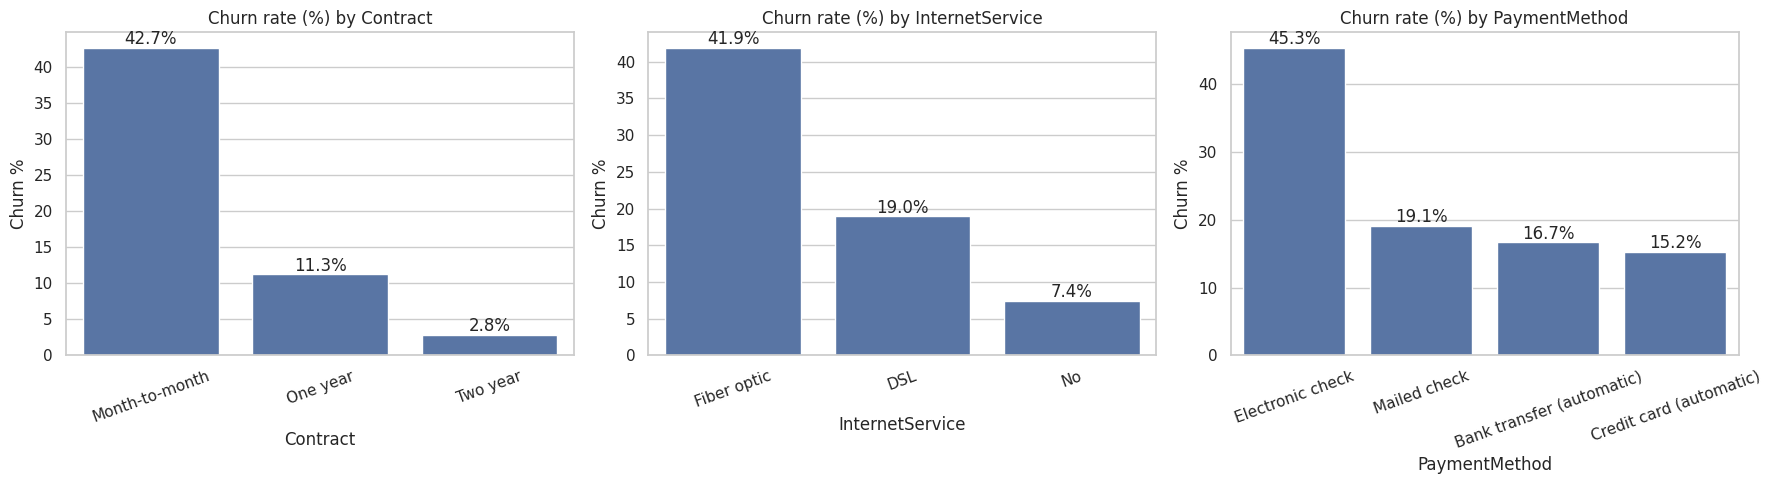

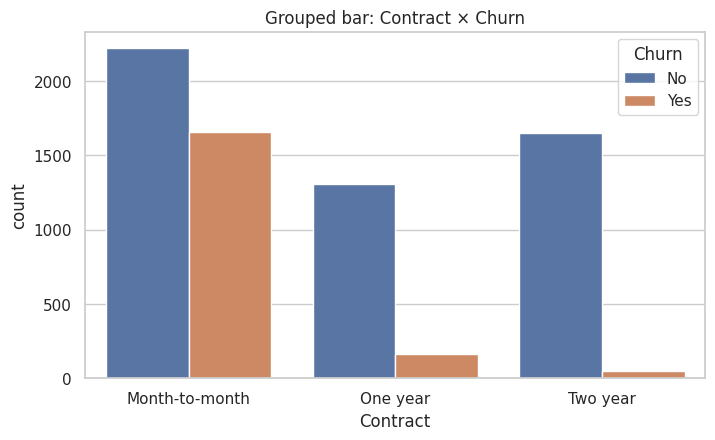

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(c)["ChurnFlag"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f"Churn rate (%) by {c}"); ax.set_ylabel("Churn %"); ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(rate.values): ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4.5))
sns.countplot(data=df, x="Contract", hue="Churn"); plt.title("Grouped bar: Contract × Churn"); plt.show()

### 5. Interpretation
- Contract: churn is 42.7% (month-to-month), 11.3% (one year) and 2.8% (two year).  
- InternetService: Fiber optic 41.9%, DSL 19.0%, No internet 7.4%.  
- PaymentMethod: Electronic check 45.3% vs 15–19% for the other three.  
- SeniorCitizen: 41.7% vs 23.6%.  
All chi-square p-values are far below 0.05 → associations are statistically significant.

### 6. Insight
Contract type is the strongest categorical relation with churn (highest Cramér's V). Churn is concentrated in *month-to-month + fibre + electronic check* customers.

### 7. AI/ML Relevance
These categoricals are strong candidates for the model; chi-square/Cramér's V gives a quick, model-free feature ranking.

## Findings Summary (Bivariate)

* Longer tenure ↔ lower churn; churners have median tenure 10 vs 38 months.
* Churners pay more per month (≈ \$80 vs ≈ \$64).
* Contract type, internet service, payment method and senior status are strongly associated with churn.
* `TotalCharges` ≈ `tenure × MonthlyCharges` → redundant numeric feature.
* **Caution:** association is not causation – e.g. electronic-check users may differ in other ways.